In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

In [7]:
df = pd.read_csv("C:\\Users\\user\\OneDrive\\Desktop\\BTCUSD-2y.csv", parse_dates=["Date"], index_col="Date")
print(df)

           Timestamp     Open     High      Low    Close    Volume
Date                                                              
2023-04-02  00:00:00  28433.1  28503.4  27843.4  28149.1  0.105614
2023-04-03  00:00:00  28149.1  28469.0  27190.2  27768.0  0.579852
2023-04-04  00:00:00  27767.9  28402.1  27633.2  28135.8  0.803473
2023-04-05  00:00:00  28134.2  28748.1  27776.1  28143.2  1.077828
2023-04-06  00:00:00  28142.5  28157.1  27684.7  28007.6  0.283230
...              ...      ...      ...      ...      ...       ...
2025-03-28  00:00:00  87174.5  87454.4  83503.7  84316.7  0.436920
2025-03-29  00:00:00  84320.9  84519.0  81557.7  82551.7  0.192708
2025-03-30  00:00:00  82559.3  83443.8  81538.2  82338.9  0.159753
2025-03-31  00:00:00  82352.4  83899.9  81260.5  82518.0  0.237001
2025-04-01  00:00:00  82516.9  85496.4  82388.9  85152.6  0.205276

[725 rows x 6 columns]


In [8]:
df = df.sort_index()

In [9]:
df["log_return"] = np.log(df["Close"] / df["Close"].shift(1))

In [10]:
df.dropna(inplace = True)

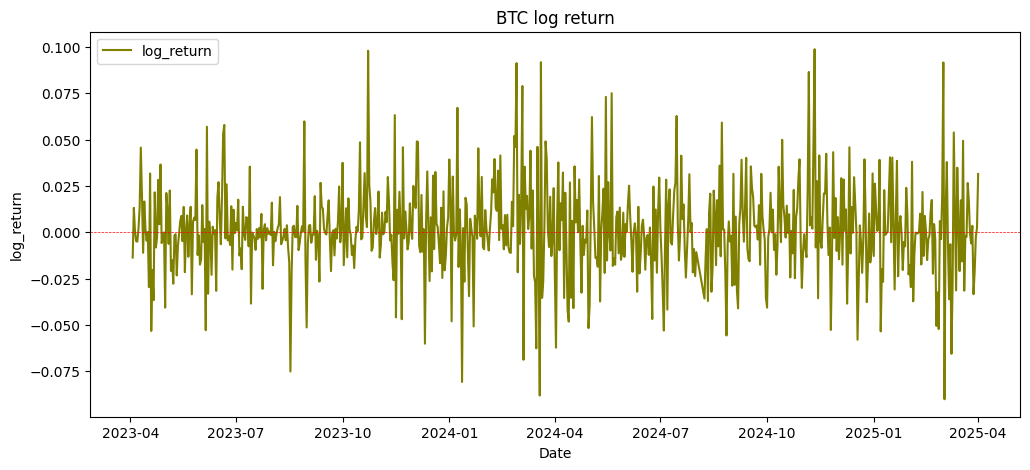

           Timestamp     Open     High      Low    Close    Volume  log_return
Date                                                                          
2023-04-03  00:00:00  28149.1  28469.0  27190.2  27768.0  0.579852   -0.013631
2023-04-04  00:00:00  27767.9  28402.1  27633.2  28135.8  0.803473    0.013159
2023-04-05  00:00:00  28134.2  28748.1  27776.1  28143.2  1.077828    0.000263
2023-04-06  00:00:00  28142.5  28157.1  27684.7  28007.6  0.283230   -0.004830
2023-04-07  00:00:00  28007.4  28076.3  27752.9  27866.8  1.123192   -0.005040


In [13]:
plt.figure(figsize=(12,5))
plt.plot(df.index, df["log_return"], label="log_return", color="olive")
plt.axhline(0, color="red", linewidth=0.5, linestyle="dashed")
plt.xlabel("Date")
plt.ylabel("log_return")
plt.title("BTC log return")
plt.legend()
plt.show()

print(df.head())

In [15]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [16]:
adf_result = adfuller(df["log_return"])
print(f"ADF Statistic: {adf_result[0]}")
print(f"p-value: {adf_result[0]}")

if adf_result[1] < 0.05:
    print("log return are stationary as fuck (reject H0).")
else:
    print("log returns are not stationary ( fial to reject H0).")

ADF Statistic: -28.548314357777148
p-value: -28.548314357777148
log return are stationary as fuck (reject H0).


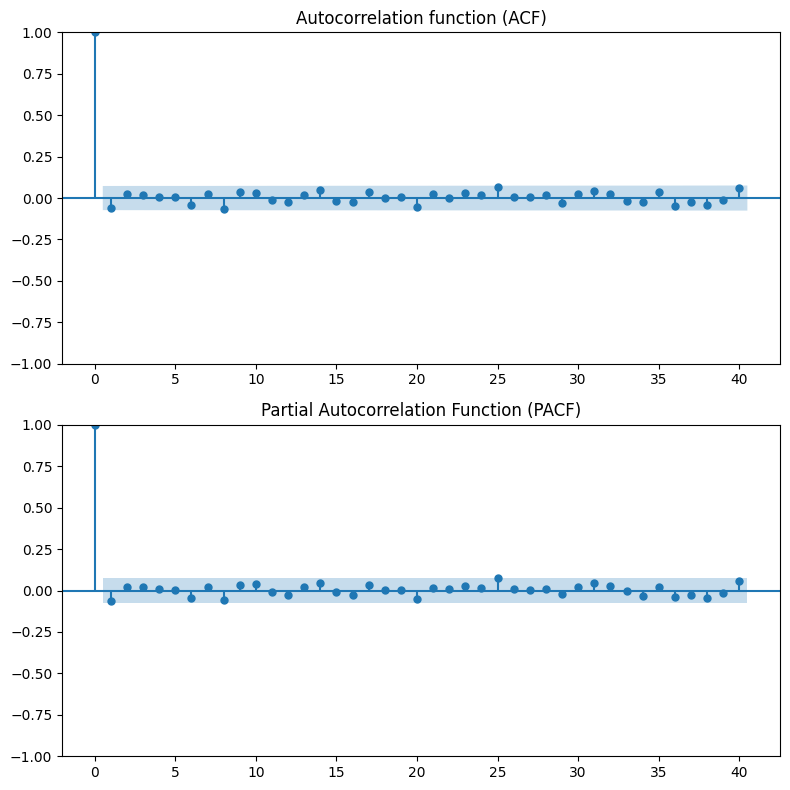

In [29]:
fig, axes = plt.subplots(2, 1, figsize=(8,8))

plot_acf(df["log_return"], ax=axes[0], lags=40)
axes[0].set_title("Autocorrelation function (ACF)")

plot_pacf(df["log_return"], ax=axes[1], lags=40)
axes[1].set_title("Partial Autocorrelation Function (PACF)")

plt.tight_layout()
plt.show()

i think both p and q equals to 1 be perfect. so we have GARCH(1,1)

In [31]:
from arch import arch_model

garch_model = arch_model(df["log_return"], vol="GARCH", p=1, q=1, dist="normal")
garch_result = garch_model.fit(disp="off")

print(garch_result.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:             log_return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:                1668.21
Distribution:                  Normal   AIC:                          -3328.43
Method:            Maximum Likelihood   BIC:                          -3310.09
                                        No. Observations:                  724
Date:                Thu, Apr 03 2025   Df Residuals:                      723
Time:                        15:13:32   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
mu         1.3487e-03  8.656e-04      1.558      0.119 

C:\Users\user\AppData\Roaming\Python\Python311\site-packages\arch\univariate\base.py:309: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.0006041. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 100 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  warnings.warn(


In [33]:
models = {
    "GARCH(1,1)": arch_model(df["log_return"], vol="GARCH", p=1, q=1),
    "GARCH(2,1)": arch_model(df["log_return"], vol="GARCH", p=2, q=1),
    "EGARCH(1,1)": arch_model(df["log_return"], vol="EGARCH", p=1, q=1),
    "GJR_GARCH(1,1)": arch_model(df["log_return"], vol="GARCH", p=1, q=1, o=1)
}

GARCH(1,1): Often works well in financial time series.

EGARCH(1,1): If AIC is lower, it suggests asymmetric volatility (e.g., volatility reacts more to negative returns).

GJR-GARCH(1,1): If this model is better, it captures leverage effects (markets crash faster than they recover).

In [ ]:
aic_bic_scores = {}
for name, model in models.items():
    result = model.fit(disp="off")
    aic_bic_scores[name] = {"aic": result.aic, "bic": result.bic}

aic_bic_df = pd.DataFrame(aic_bic_scores).T
print(aic_bic_df.sort_values(by="aic"))       # Lower AIC is better

                        aic          bic
EGARCH(1,1)    -3329.456847 -3311.117682
GARCH(1,1)     -3328.426957 -3310.087792
GJR_GARCH(1,1) -3328.374835 -3305.450878
GARCH(2,1)     -3327.746659 -3304.822702


C:\Users\user\AppData\Roaming\Python\Python311\site-packages\arch\univariate\base.py:309: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.0006041. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 100 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  warnings.warn(
C:\Users\user\AppData\Roaming\Python\Python311\site-packages\arch\univariate\base.py:309: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.0006041. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 100 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  warnings.warn(
C:\Users\user\AppData\Roaming\Python\Pyt

Residual Analysis

In [37]:
import seaborn as sns
from statsmodels.stats.diagnostic import acorr_ljungbox

In [38]:
residuals = garch_result.resid
standardized_residulas = residuals / garch_result.conditional_volatility

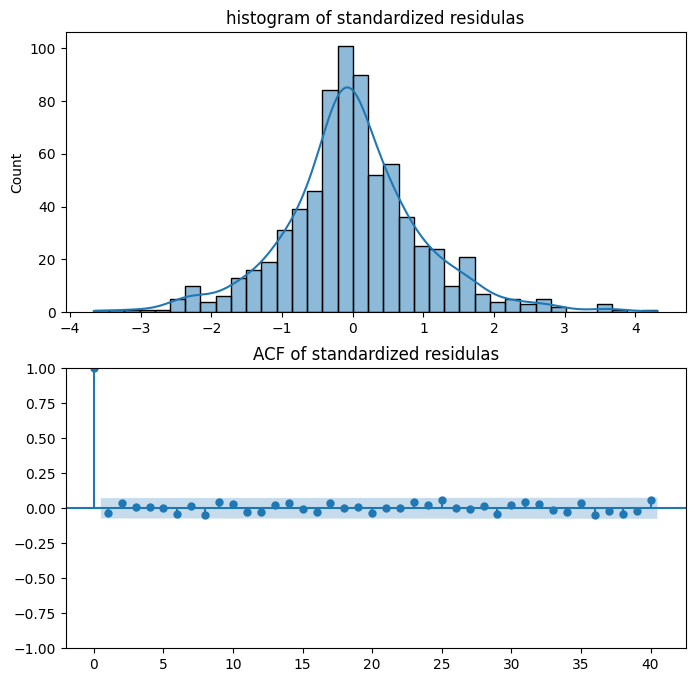

In [43]:
fig, axes = plt.subplots(2,1, figsize=(8,8))
sns.histplot(standardized_residulas, kde = True, ax=axes[0])
axes[0].set_title("histogram of standardized residulas")

plot_acf(standardized_residulas, ax=axes[1], lags=40)
axes[1].set_title("ACF of standardized residulas")

plt.show()

Key Observations:
Bell-Shaped & Symmetric (Good Model) ✅

If the histogram looks like a normal distribution (Gaussian), the model fits well.

A smooth KDE curve overlapping a bell-shaped histogram is a good sign.

Fat Tails (Volatility Underestimation) 🔴

If the histogram has thicker tails than a normal curve, the model underestimates extreme movements.

Solution: Use Student’s t-distribution instead of "normal" in arch_model(..., dist="t").

Skewed Left or Right (Asymmetry) 🔴

If the histogram is skewed (more values on one side), the model doesn't capture asymmetry well.

Solution: Try EGARCH or GJR-GARCH.

We predict the next 30 days of volatility based on the selected GARCH model.

In [51]:
forecast_horizon = 30
garch_forecast = garch_result.forecast(start=df.index[-1], horizon = forecast_horizon)

In [52]:
forecast_volatility = np.sqrt(garch_forecast.variance.values[-1, :])

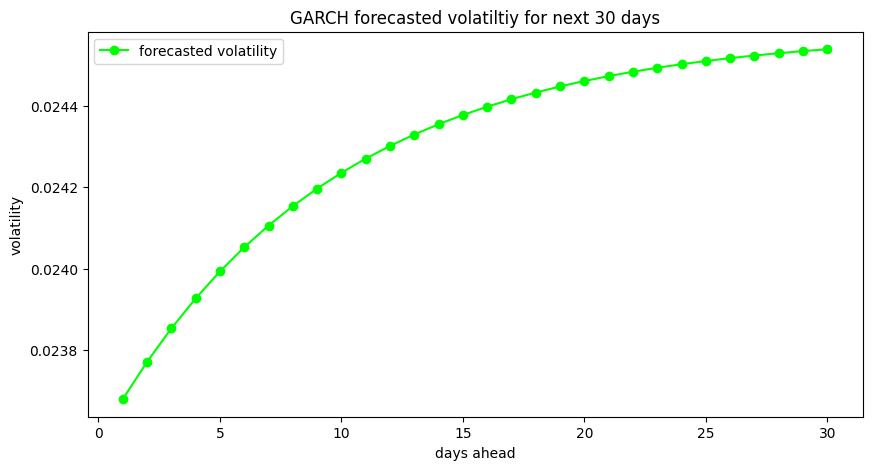

In [53]:
plt.figure(figsize=(10,5))
plt.plot(range(1, forecast_horizon +1), forecast_volatility, marker="o", linestyle="-", color="lime", label="forecasted volatility")

plt.xlabel("days ahead")
plt.ylabel("volatility")
plt.title("GARCH forecasted volatiltiy for next 30 days")

plt.legend()
plt.show()

as a tip i have to say that garch model usually overfittted for long ranges and we can just use of its early ahead(i mean like till 5 or 8 days ahead)

Simulating Future BTC Price:

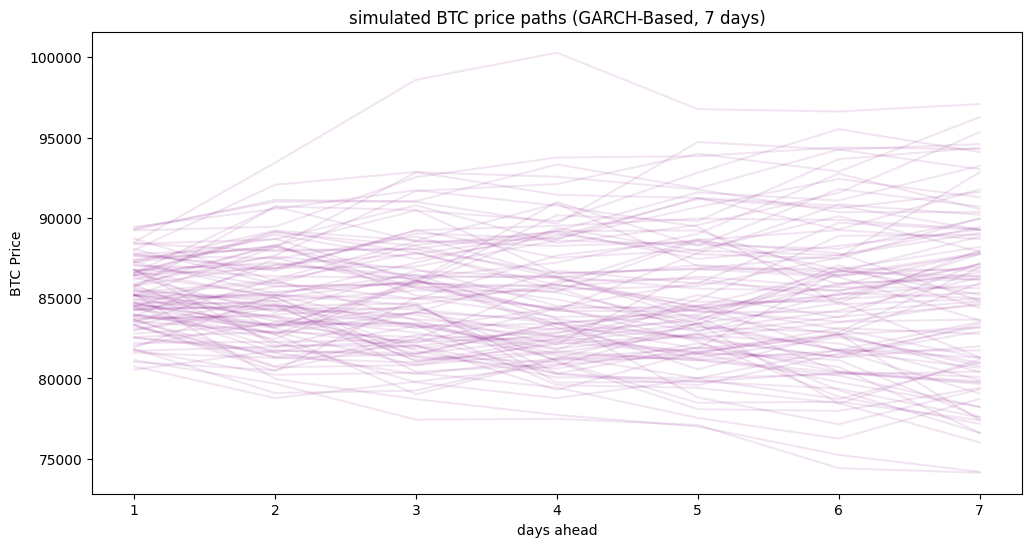

In [55]:
num_simulations = 1000
num_days = 7

last_price = df["Close"].iloc[-1]
simulated_prices = np.zeros((num_simulations, num_days))

for i in range(num_simulations):
    simulated_returns = np.random.normal(0, forecast_volatility[:num_days])
    simulated_prices[i] = last_price * np.cumprod(np.exp(simulated_returns))

plt.figure(figsize=(12,6))
for i in range(100):
    plt.plot(range(1, num_days + 1), simulated_prices[i], alpha=0.1, color="purple")

plt.xlabel("days ahead")
plt.ylabel("BTC Price")
plt.title("simulated BTC price paths (GARCH-Based, 7 days)")
plt.show()

compute VAR and Es (Expected Shortfall - Average loss beyond VaR) from Simulated returns

In [56]:
confidence_lvl = 0.05 #95 percent confidence ==> 5% tail risk

simulated_returns = np.log(simulated_prices[:, -1] / last_price)

var_95 = np.percentile(simulated_returns, confidence_lvl*100)
print(f"95% value at risk (VAR): {var_95:.4f}")

es_95 = simulated_returns[simulated_returns <= var_95].mean()
print(f"95% Expected shortfall (ES): {es_95:.4f}")

95% value at risk (VAR): -0.1056
95% Expected shortfall (ES): -0.1305


VaR @ 95%: "There is a 5% chance that Bitcoin will lose at least {var_95:.4f} (as a fraction of its value) over the next 7 days."

ES @ 95%: "If Bitcoin's losses exceed VaR, the expected loss is {es_95:.4f}."



Backtesting VaR: will help you verify how well your model would have predicted risk over a historical period. We'll compare the actual losses to the VaR at various confidence levels (e.g., 95%, 99%) and see if the VaR holds up in real-world data.

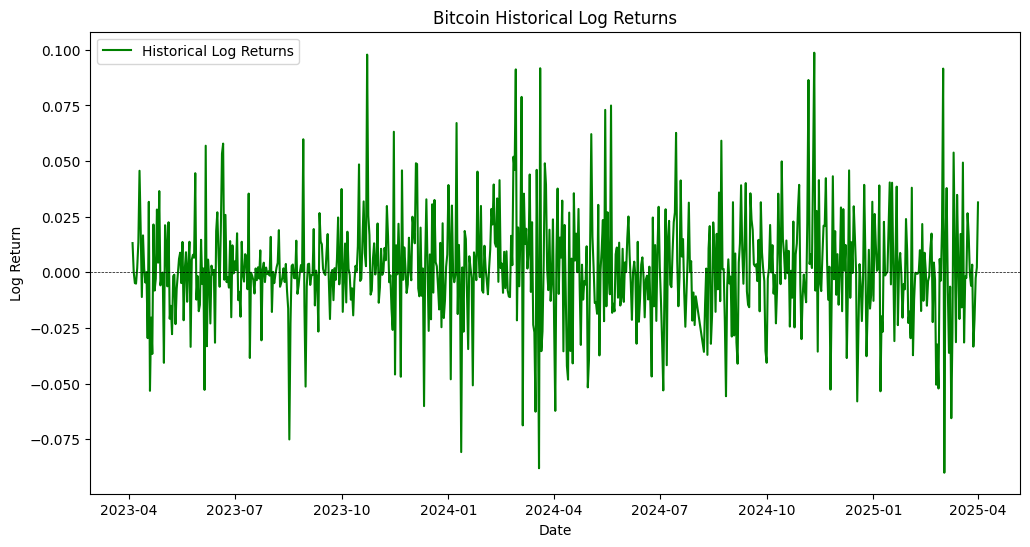

In [ ]:
df["historical_return"] = np.log(df["Close"] / df["Close"].shift(1))

df.dropna(inplace=True)

plt.figure(figsize=(12, 6))
plt.plot(df.index, df["historical_return"], label="Historical Log Returns", color="green")
plt.axhline(0, color="black", linewidth=0.5, linestyle="dashed")
plt.xlabel("Date")
plt.ylabel("Log Return")
plt.title("Bitcoin Historical Log Returns")
plt.legend()
plt.show()


Historical VaR @ 95%: -0.0373


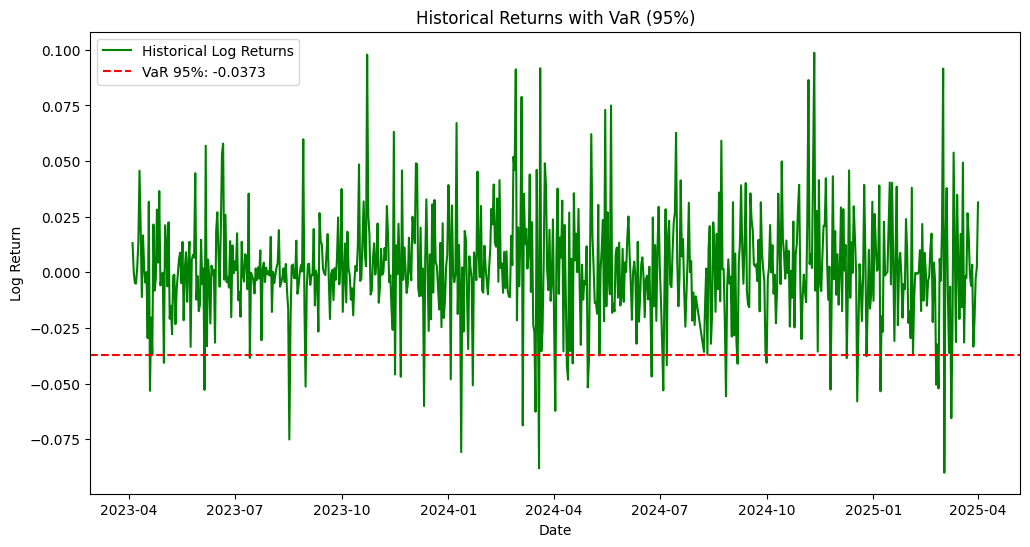

In [ ]:
# Calculate the 5th percentile of historical returns for VaR at 95% confidence
var_95_historical = np.percentile(df["historical_return"], 5)
print(f"Historical VaR @ 95%: {var_95_historical:.4f}")

plt.figure(figsize=(12, 6))
plt.plot(df.index, df["historical_return"], label="Historical Log Returns", color="green")
plt.axhline(var_95_historical, color="red", linestyle="--", label=f"VaR 95%: {var_95_historical:.4f}")
plt.xlabel("Date")
plt.ylabel("Log Return")
plt.title("Historical Returns with VaR (95%)")
plt.legend()
plt.show()


In [59]:
# Count violations (actual returns below VaR)
violations = df["historical_return"] < var_95_historical
num_violations = violations.sum()
total_days = len(df)

# Violation ratio
violation_ratio = num_violations / total_days
print(f"VaR Violations: {num_violations} out of {total_days} days ({violation_ratio * 100:.2f}% of the time)")

# If the VaR model is correct, the violation ratio should be close to the confidence level (5% for 95% VaR).


VaR Violations: 37 out of 723 days (5.12% of the time)


interpretation of risk management results:

Violation Ratio: Ideally, the violation ratio should be close to the confidence level (e.g., 5% for 95% VaR).

If the ratio is higher than expected, the model underestimates risk, meaning you could have been exposed to more risk than anticipated.

If the ratio is lower, the model may be too conservative.